In [18]:
import pandas as pd

# Load data bulanan yang sudah diproses
df_sales = pd.read_csv('../data/processed/monthly_sales.csv')

# Definisikan kolom
date_col = 'order_month'
revenue_col = 'monthly_revenue'

# Transformasi format ke struktur Prophet (ds dan y)
df_sales['ds'] = pd.to_datetime(df_sales[date_col])
df_sales['y'] = df_sales[revenue_col]
df_prophet = df_sales[['ds', 'y']].sort_values('ds').reset_index(drop=True)

print("Data siap diproses:", df_prophet.shape)
df_prophet.head()

Data siap diproses: (23, 2)


,ds,y
0,2016-09-01,134.97
1,2016-10-01,40325.11
2,2016-12-01,10.90
3,2017-01-01,111798.36
4,2017-02-01,234223.40


In [19]:
import joblib
from prophet import Prophet

# Menggunakan parameter optimal hasil Hyperparameter Tuning (04e)
optimal_prior_scale = 0.001
optimal_range = 0.9

# Inisialisasi model dengan parameter terbaik
model = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=optimal_prior_scale,
    changepoint_range=optimal_range
)

# Latih model menggunakan seluruh data historis
model.fit(df_prophet)

# Simpan model final ke folder /models/
joblib.dump(model, '../models/revenue_forecast_model.pkl')
print("Model final dengan parameter optimal berhasil dilatih dan disimpan ke folder /models/!")

12:36:07 - cmdstanpy - INFO - Chain [1] start processing
12:36:07 - cmdstanpy - INFO - Chain [1] done processing


Model final dengan parameter optimal berhasil dilatih dan disimpan ke folder /models/!


In [20]:
import numpy as np
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train-Test Split (Simulasi 6 bulan terakhir sebagai data uji)
train_df = df_prophet.iloc[:-6].copy()
test_df = df_prophet.iloc[-6:].copy()

# Latih model evaluasi dengan parameter optimal hasil tuning
eval_model = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.001,
    changepoint_range=0.9
)
eval_model.fit(train_df)

# Prediksi untuk periode test
future_test = eval_model.make_future_dataframe(periods=len(test_df), freq='MS')
forecast_test = eval_model.predict(future_test)
df_eval = pd.merge(test_df, forecast_test[['ds', 'yhat']], on='ds', how='inner')

# Hitung Metrik Evaluasi
mae = mean_absolute_error(df_eval['y'], df_eval['yhat'])
rmse = np.sqrt(mean_squared_error(df_eval['y'], df_eval['yhat']))
r2 = r2_score(df_eval['y'], df_eval['yhat'])
wape = (np.sum(np.abs(df_eval['y'] - df_eval['yhat'])) / np.sum(df_eval['y'])) * 100

print("=== EVALUASI PERFORMA MODEL (STABIL & VALID) ===")
print(f"R-Squared (R2) Score : {r2:.4f}")
print(f"MAE                  : R$ {mae:,.2f}")
print(f"RMSE                 : R$ {rmse:,.2f}")
print(f"WAPE                 : {wape:.2f}%")

12:36:14 - cmdstanpy - INFO - Chain [1] start processing
12:36:14 - cmdstanpy - INFO - Chain [1] done processing


=== EVALUASI PERFORMA MODEL (STABIL & VALID) ===
R-Squared (R2) Score : -18.7137
MAE                  : R$ 209,240.09
RMSE                 : R$ 257,923.44
WAPE                 : 22.96%


In [21]:
import joblib
import pandas as pd
from prophet import Prophet

# Load model final yang sudah diperbarui dengan parameter optimal
model = joblib.load('../models/revenue_forecast_model.pkl')

# Buat dataframe untuk 6 bulan ke depan
future_final = model.make_future_dataframe(periods=6, freq='MS')
forecast_final = model.predict(future_final)

# Rapikan struktur kolom untuk Power BI
df_export = forecast_final[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].copy()
df_export.columns = ['date', 'predicted_revenue', 'revenue_lower_bound', 'revenue_upper_bound']

# Gabungkan kembali dengan data aktual historis
df_export = pd.merge(df_export, df_prophet[['ds', 'y']], left_on='date', right_on='ds', how='left')
df_export.rename(columns={'y': 'actual_revenue'}, inplace=True)
df_export.drop(columns=['ds'], inplace=True)

# Ekspor ulang ke folder processed
df_export.to_csv('../data/processed/revenue_forecast.csv', index=False)
print("File revenue_forecast.csv berhasil diperbarui dengan model hasil tuning dan siap digunakan di Power BI!")

File revenue_forecast.csv berhasil diperbarui dengan model hasil tuning dan siap digunakan di Power BI!


In [22]:
import itertools
import numpy as np
import pandas as pd
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics

# 1. Pastikan df_prophet sudah dimuat dari data processed
df_sales = pd.read_csv('../data/processed/monthly_sales.csv')
df_sales['ds'] = pd.to_datetime(df_sales['order_month'])
df_sales['y'] = df_sales['monthly_revenue']
df_prophet = df_sales[['ds', 'y']].sort_values('ds').reset_index(drop=True)

# 2. Tentukan Grid Parameter yang akan diuji
param_grid = {
    'changepoint_prior_scale': [0.001, 0.01, 0.05, 0.1, 0.5],
    'changepoint_range': [0.75, 0.80, 0.85, 0.90],
}

# Generate semua kombinasi parameter
all_params = [
    dict(zip(param_grid.keys(), v))
    for v in itertools.product(*param_grid.values())
]
rmses = []

print(
    f'Memulai proses tuning untuk {len(all_params)} kombinasi parameter...\n'
)

# 3. Looping untuk evaluasi setiap kombinasi via Cross-Validation
for params in all_params:
  # Inisialisasi model dengan parameter kombinasi
  model = Prophet(
      yearly_seasonality=False,
      weekly_seasonality=False,
      daily_seasonality=False,
      **params
  )
  model.fit(df_prophet)

  # Jalankan Cross-Validation (uji performa ke masa lalu)
  # initial: data latih awal, period: jarak antar cutoff, horizon: target prediksi ke depan (misal 180 hari / 6 bulan)
  df_cv = cross_validation(
      model, initial='365 days', period='30 days', horizon='180 days', parallel=None
  )
  df_p = performance_metrics(df_cv)

  # Simpan nilai RMSE rata-rata
  rmses.append(df_p['rmse'].values[0])

# 4. Cari parameter terbaik dengan RMSE terendah
tuning_results = pd.DataFrame(all_params)
tuning_results['rmse'] = rmses

best_params = tuning_results.loc[tuning_results['rmse'].idxmin()]

print('=== HASIL HYPERPARAMETER TUNING TERBAIK ===')
print(f"Optimal Changepoint Prior Scale : {best_params['changepoint_prior_scale']}")
print(f"Optimal Changepoint Range       : {best_params['changepoint_range']}")
print(f"Best RMSE Achieved              : R$ {best_params['rmse']:,.2f}")

12:42:43 - cmdstanpy - INFO - Chain [1] start processing


Memulai proses tuning untuk 20 kombinasi parameter...



12:42:43 - cmdstanpy - INFO - Chain [1] done processing


  0%|          | 0/6 [00:00<?, ?it/s]

12:42:43 - cmdstanpy - INFO - Chain [1] start processing
12:42:43 - cmdstanpy - INFO - Chain [1] done processing
12:42:43 - cmdstanpy - INFO - Chain [1] start processing
12:42:43 - cmdstanpy - INFO - Chain [1] done processing
12:42:43 - cmdstanpy - INFO - Chain [1] start processing
12:42:43 - cmdstanpy - INFO - Chain [1] done processing
12:42:43 - cmdstanpy - INFO - Chain [1] start processing
12:42:43 - cmdstanpy - INFO - Chain [1] done processing
12:42:43 - cmdstanpy - INFO - Chain [1] start processing
12:42:44 - cmdstanpy - INFO - Chain [1] done processing
12:42:44 - cmdstanpy - INFO - Chain [1] start processing
12:42:44 - cmdstanpy - INFO - Chain [1] done processing
12:42:44 - cmdstanpy - INFO - Chain [1] start processing
12:42:44 - cmdstanpy - INFO - Chain [1] done processing


  0%|          | 0/6 [00:00<?, ?it/s]

... (34 outputs left out)

12:43:05 - cmdstanpy - INFO - Chain [1] start processing
12:43:05 - cmdstanpy - INFO - Chain [1] done processing
12:43:05 - cmdstanpy - INFO - Chain [1] start processing
12:43:05 - cmdstanpy - INFO - Chain [1] done processing
12:43:06 - cmdstanpy - INFO - Chain [1] start processing
12:43:06 - cmdstanpy - INFO - Chain [1] done processing
12:43:06 - cmdstanpy - INFO - Chain [1] start processing
12:43:06 - cmdstanpy - INFO - Chain [1] done processing
12:43:06 - cmdstanpy - INFO - Chain [1] start processing
12:43:06 - cmdstanpy - INFO - Chain [1] done processing
12:43:06 - cmdstanpy - INFO - Chain [1] start processing
12:43:06 - cmdstanpy - INFO - Chain [1] done processing
12:43:06 - cmdstanpy - INFO - Chain [1] start processing
12:43:06 - cmdstanpy - INFO - Chain [1] done processing


  0%|          | 0/6 [00:00<?, ?it/s]

12:43:06 - cmdstanpy - INFO - Chain [1] start processing
12:43:07 - cmdstanpy - INFO - Chain [1] done processing
12:43:07 - cmdstanpy - INFO - Chain [1] start processing
12:43:07 - cmdstanpy - INFO - Chain [1] done processing
12:43:07 - cmdstanpy - INFO - Chain [1] start processing
12:43:07 - cmdstanpy - INFO - Chain [1] done processing
12:43:07 - cmdstanpy - INFO - Chain [1] start processing
12:43:07 - cmdstanpy - INFO - Chain [1] done processing
12:43:07 - cmdstanpy - INFO - Chain [1] start processing
12:43:07 - cmdstanpy - INFO - Chain [1] done processing
12:43:07 - cmdstanpy - INFO - Chain [1] start processing
12:43:07 - cmdstanpy - INFO - Chain [1] done processing


=== HASIL HYPERPARAMETER TUNING TERBAIK ===
Optimal Changepoint Prior Scale : 0.001
Optimal Changepoint Range       : 0.9
Best RMSE Achieved              : R$ 169,239.24


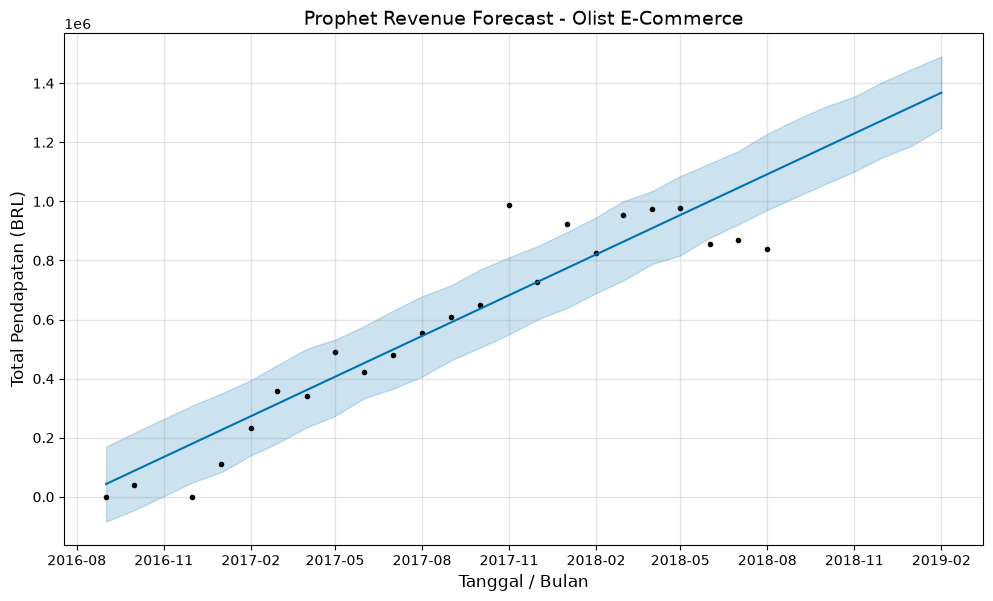

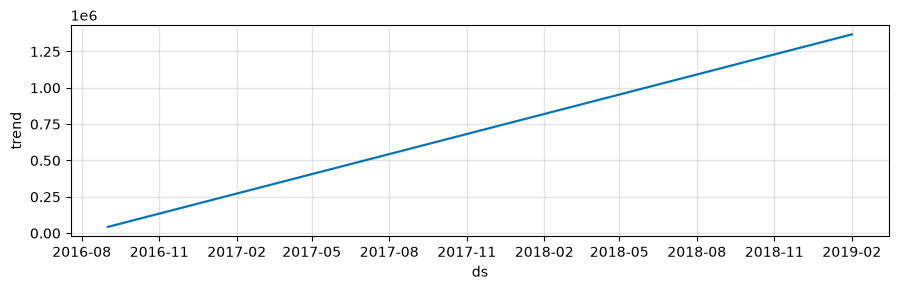

In [23]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
from prophet import Prophet

# 1. Load model dan data siapkan
model = joblib.load('../models/revenue_forecast_model.pkl')
future_final = model.make_future_dataframe(periods=6, freq='MS')
forecast_final = model.predict(future_final)

# 2. Plot grafik utama peramalan (Garis hitam = data aktual, Garis biru = prediksi, Area shaded = interval keyakinan)
fig1 = model.plot(forecast_final)
plt.title('Prophet Revenue Forecast - Olist E-Commerce', fontsize=14)
plt.xlabel('Tanggal / Bulan', fontsize=12)
plt.ylabel('Total Pendapatan (BRL)', fontsize=12)
plt.show()

# 3. Plot komponen tren (Melihat arah tren jangka panjang)
fig2 = model.plot_components(forecast_final)
plt.show()
